
 TEST 1: XOR
Input: [[0 0]
 [0 1]
 [1 0]
 [1 1]] 
Actual: [  0 100 100   0] 
Predicted: [ 33.22  33.22 100.    33.22]

 TEST 2: Small Network
Input: [[2 9]
 [1 5]
 [3 6]] 
Actual: [92 86 89] 
Predicted: [125.43  73.94  98.37]

 TEST 3: Training Error
Input: [[2 9]
 [1 5]
 [3 6]] 
Actual: [92 86 89] 
Predicted: [118.1   69.48  96.13]
Epoch 1: 3884.744101
Epoch 10: 2870.416408
Final MSE: 335.140994


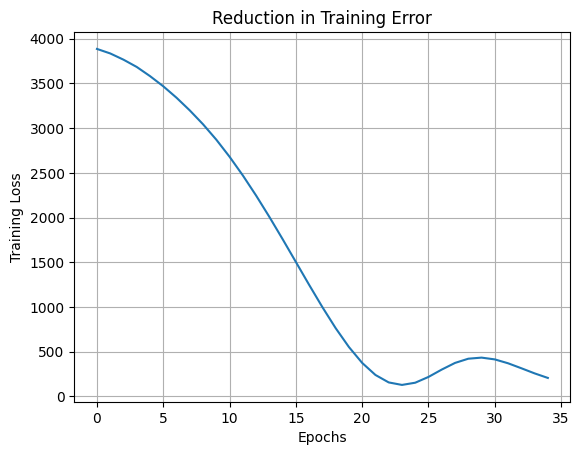

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

def show(title, x, y, h=3, lr=0.1, ep=10000):
    print("\n", title)
    m = MLPRegressor(hidden_layer_sizes=(h,), learning_rate_init=lr,
                     max_iter=ep, random_state=42)
    m.fit(x, y)
    p = m.predict(x)
    print("Input:", x, "\nActual:", y, "\nPredicted:", np.round(p, 2))
    return m, p

x1 = np.array([[0,0],[0,1],[1,0],[1,1]])
y1 = np.array([0,100,100,0])
show("TEST 1: XOR", x1, y1)

x = np.array([[2,9],[1,5],[3,6]])
y = np.array([92,86,89])

show("TEST 2: Small Network", x, y, h=1)
m, p = show("TEST 3: Training Error", x, y)

loss = m.loss_curve_
for e in [1,10,50,100,500,1000,5000]:
    if e <= len(loss):
        print(f"Epoch {e}: {loss[e-1]:.6f}")

print("Final MSE:", round(mean_squared_error(y,p),6))
plt.plot(loss)
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Reduction in Training Error")
plt.grid()
plt.show()